<a href="https://colab.research.google.com/github/dennis-langat21/School-Management/blob/master/Bank_Marketing_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Assignment 1:
##Exploratory Data Analysis (EDA)
Bank Marketing Dataset

1.DATA LOADING & CLEANING


In [32]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

with zipfile.ZipFile("Bank.zip") as z:

    # Finding the CSV file inside the ZIP
    csv_file = next(
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    )

    # Loading the dataset
    with z.open(csv_file) as f:
        df = pd.read_csv(f, sep=";")

# Displaying the dataset
print("Dataset shape:", df.shape)
df.head()

#Variable names and data types
print("Variable names and data types:")
display(df.dtypes.to_frame("Data Type"))

#Number of observations and variables
print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

#Missing values and their proportions
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Proportion (%)": (df.isnull().mean() * 100).round(2)
})

display(missing)

Dataset shape: (45214, 17)
Variable names and data types:


,Data Type
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64


Number of observations: 45214
Number of variables: 17


,Missing Values,Missing Proportion (%)
age,0,0.00
job,0,0.00
marital,0,0.00
education,0,0.00
default,0,0.00
balance,0,0.00
housing,0,0.00
loan,0,0.00
contact,0,0.00
day,0,0.00


##2. UNIVARIATE DATA DESCRIPTION


,count,mean,std,min,25%,50%,75%,max
age,45214.0,40.936524,10.618689,18.0,33.0,39.0,48.0,95.0
balance,45214.0,1362.246517,3044.674703,-8019.0,72.0,448.0,1428.0,102127.0
day,45214.0,15.805768,8.322583,1.0,8.0,16.0,21.0,31.0
duration,45210.0,258.152511,257.520272,0.0,103.0,180.0,319.0,4918.0
campaign,45214.0,2.763768,3.097941,1.0,1.0,2.0,3.0,63.0
pdays,45214.0,40.195094,100.125986,-1.0,-1.0,-1.0,-1.0,871.0
previous,45214.0,0.580285,2.303369,0.0,0.0,0.0,0.0,275.0


,Median
age,39.0
balance,448.0
day,16.0
duration,180.0
campaign,2.0
pdays,-1.0
previous,0.0


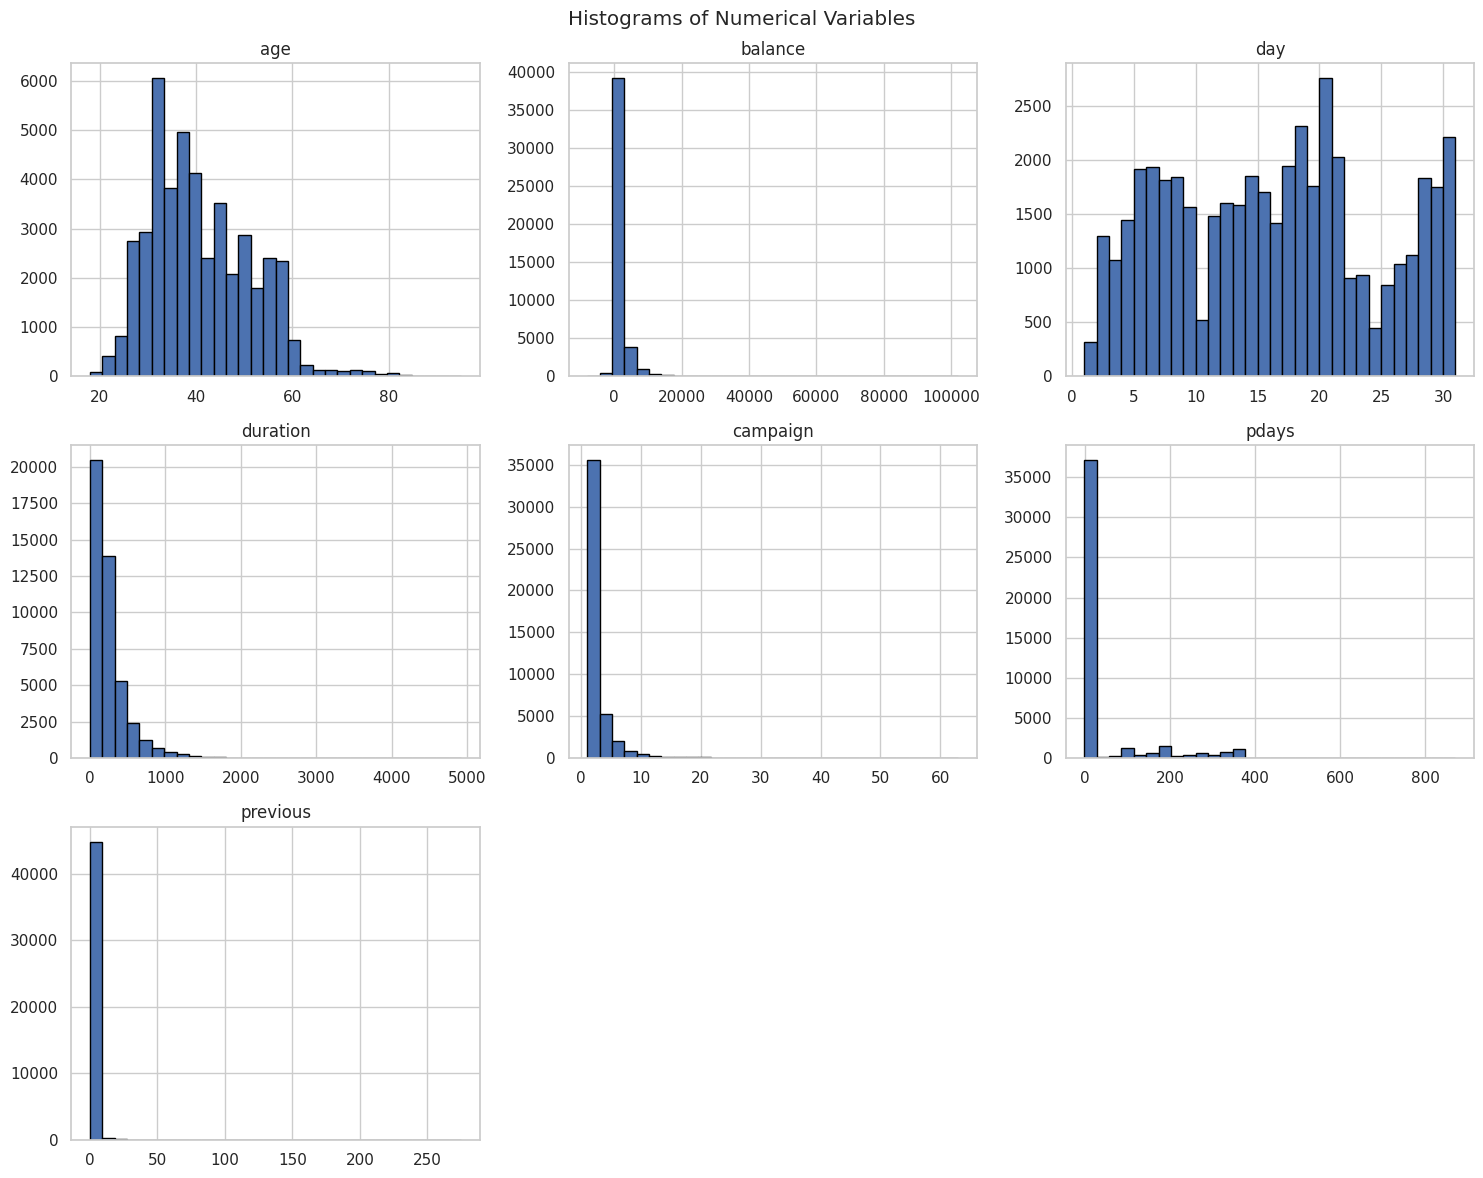

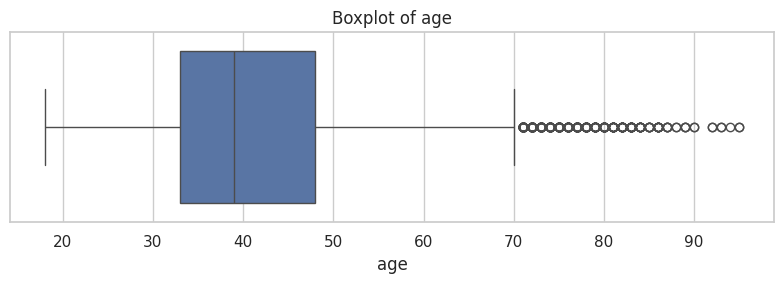

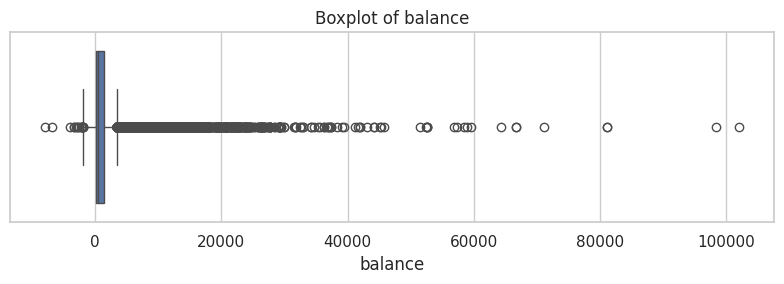

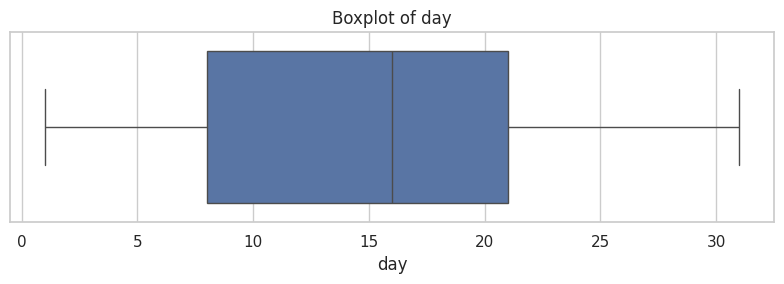

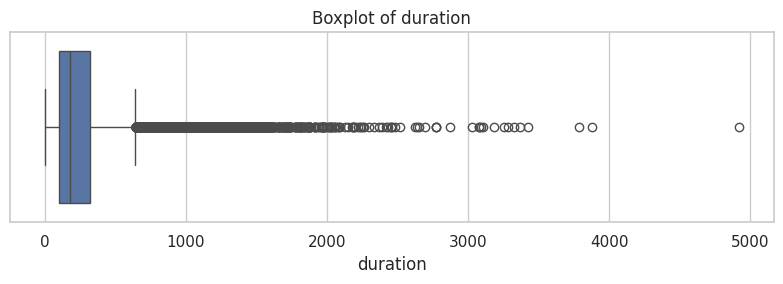

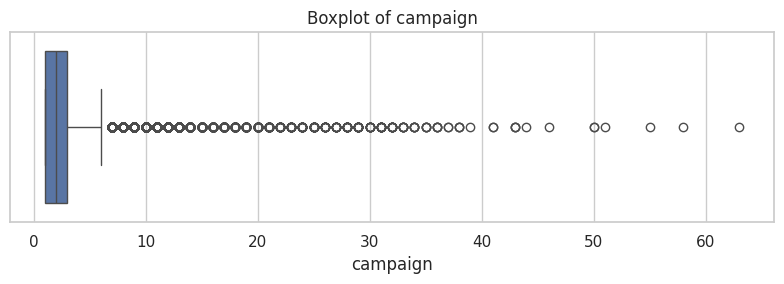

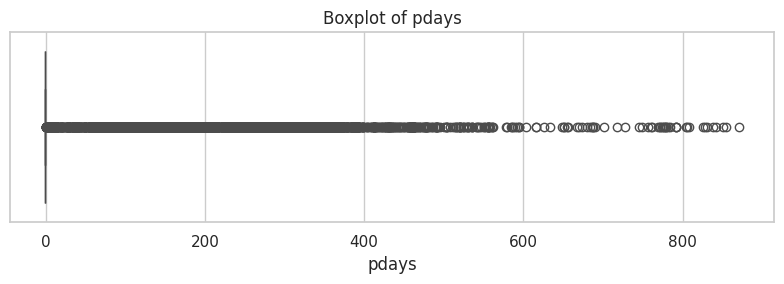

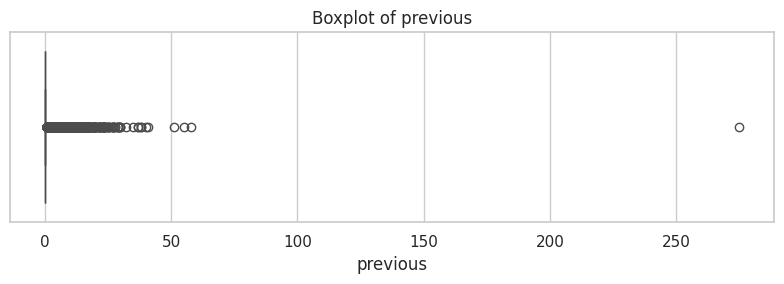


Frequency table for job:


,Frequency
job,
blue-collar,9732
management,9460
technician,7597
admin.,5172
services,4154
retired,2264
self-employed,1579
entrepreneur,1487
unemployed,1303


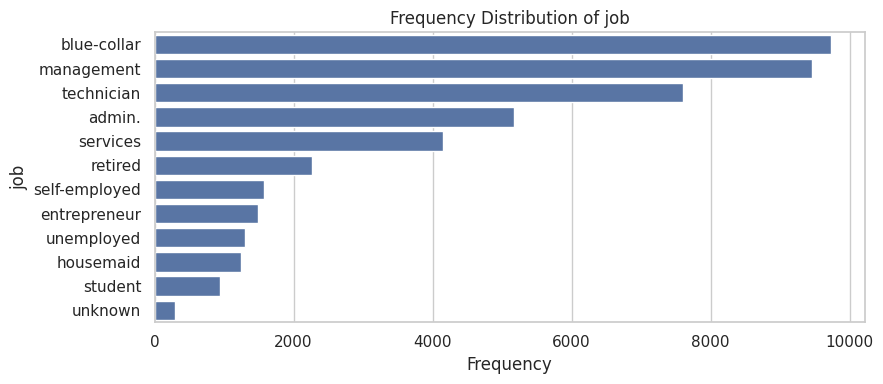

Most frequent category in job: blue-collar
Frequency: 9732

Frequency table for marital:


,Frequency
marital,
married,27217
single,12790
divorced,5207


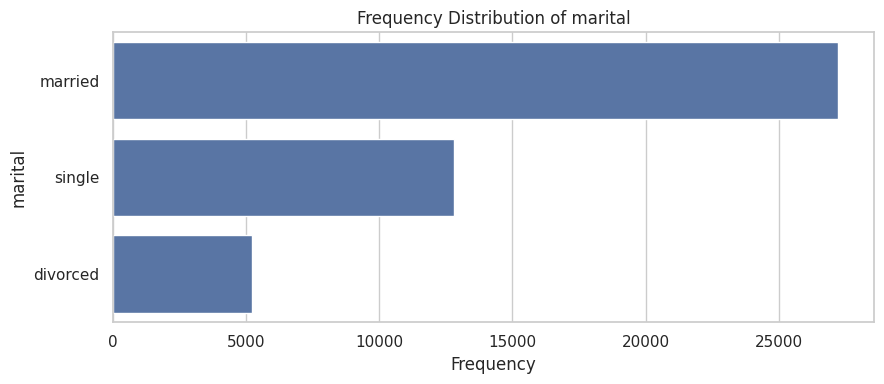

Most frequent category in marital: married
Frequency: 27217

Frequency table for education:


,Frequency
education,
secondary,23203
tertiary,13303
primary,6851
unknown,1857


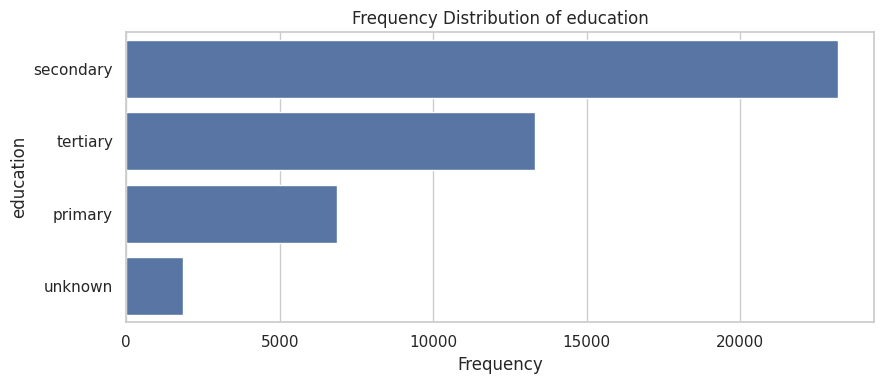

Most frequent category in education: secondary
Frequency: 23203

Frequency table for default:


,Frequency
default,
no,44399
yes,815


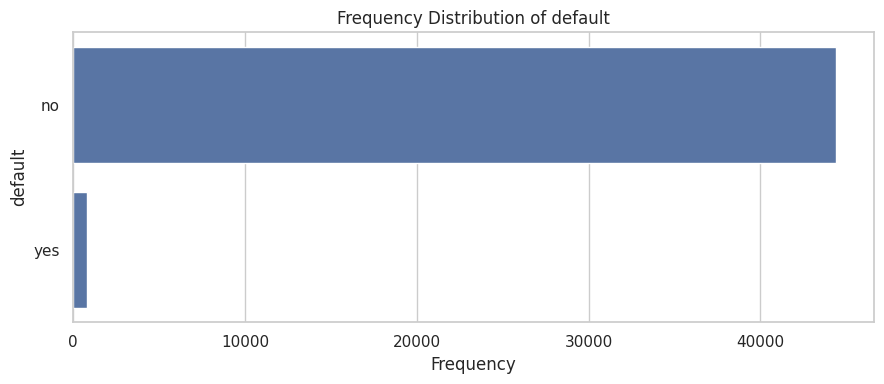

Most frequent category in default: no
Frequency: 44399

Frequency table for housing:


,Frequency
housing,
yes,25132
no,20082


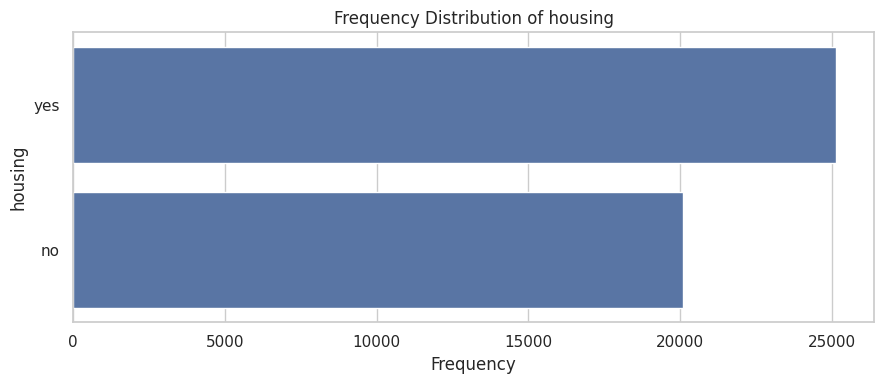

Most frequent category in housing: yes
Frequency: 25132

Frequency table for loan:


,Frequency
loan,
no,37969
yes,7245


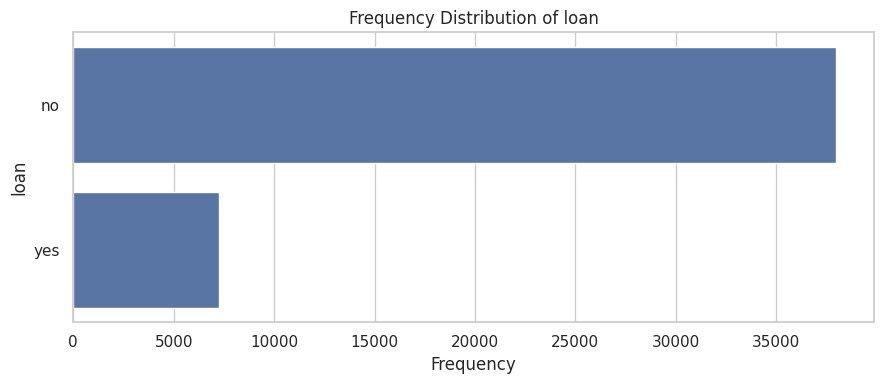

Most frequent category in loan: no
Frequency: 37969

Frequency table for contact:


,Frequency
contact,
cellular,29285
unknown,13023
telephone,2906


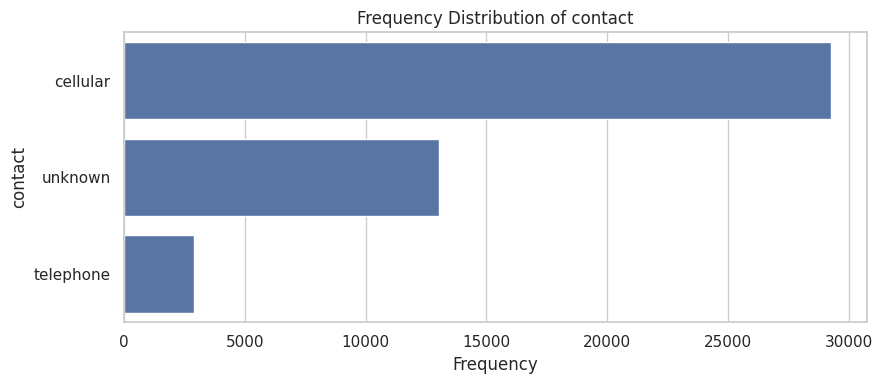

Most frequent category in contact: cellular
Frequency: 29285

Frequency table for month:


,Frequency
month,
may,13769
jul,6895
aug,6247
jun,5341
nov,3970
apr,2932
feb,2649
jan,1403
oct,738


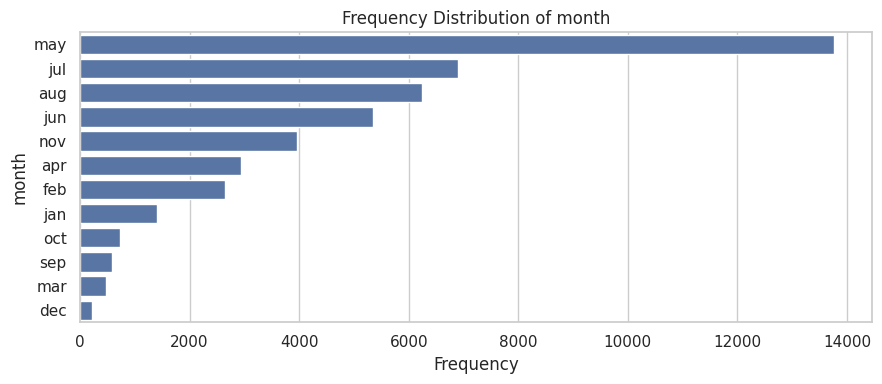

Most frequent category in month: may
Frequency: 13769

Frequency table for poutcome:


,Frequency
poutcome,
unknown,36962
failure,4901
other,1840
success,1511


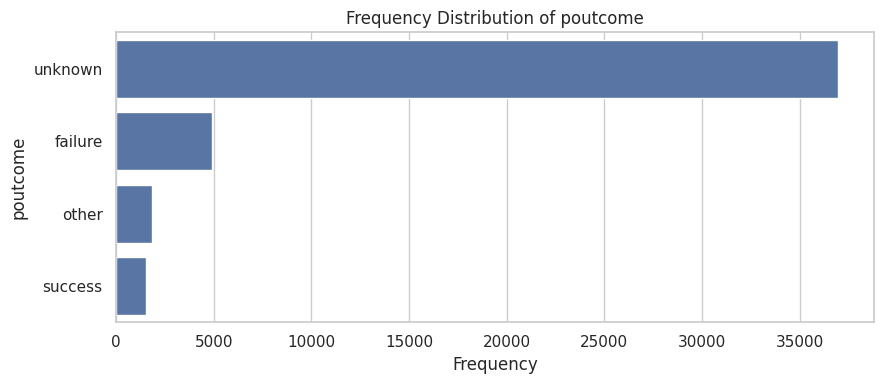

Most frequent category in poutcome: unknown
Frequency: 36962

Frequency table for y:


,Frequency
y,
no,39925
yes,5289


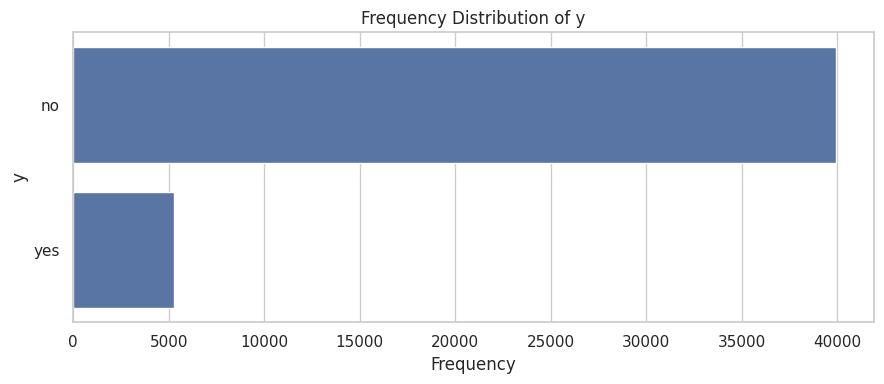

Most frequent category in y: no
Frequency: 39925


In [33]:
# Identify numerical variables
numeric_cols = df.select_dtypes(include="number").columns

# Calculate descriptive statistics
display(df[numeric_cols].describe().T)
display(df[numeric_cols].median().to_frame("Median"))

# Identify categorical variables
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns



# Histograms
df[numeric_cols].hist(
    bins=30,
    figsize=(15, 12),
    edgecolor="black"
)
plt.suptitle("Histograms of Numerical Variables")
plt.tight_layout()
plt.show()


# Boxplots
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

#Frequency Tables and Bar Charts
for col in categorical_cols:
    print(f"\nFrequency table for {col}:")
    display(df[col].value_counts(dropna=False).to_frame("Frequency"))
    counts = df[col].value_counts()

    plt.figure(figsize=(9, 4))
    sns.barplot(x=counts.values, y=counts.index)

    plt.title(f"Frequency Distribution of {col}")
    plt.xlabel("Frequency")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

    print(f"Most frequent category in {col}: {counts.idxmax()}")
    print(f"Frequency: {counts.max()}")

##3. BIVARIATE AND MULTIVARIATE DESCRIPTION

Correlation Matrix:


,age,balance,day,duration,campaign,pdays,previous
age,1.00,0.10,-0.01,-0.00,0.00,-0.02,0.00
balance,0.10,1.00,0.00,0.02,-0.01,0.00,0.02
day,-0.01,0.00,1.00,-0.03,0.16,-0.09,-0.05
duration,-0.00,0.02,-0.03,1.00,-0.08,-0.00,0.00
campaign,0.00,-0.01,0.16,-0.08,1.00,-0.09,-0.03
pdays,-0.02,0.00,-0.09,-0.00,-0.09,1.00,0.45
previous,0.00,0.02,-0.05,0.00,-0.03,0.45,1.00


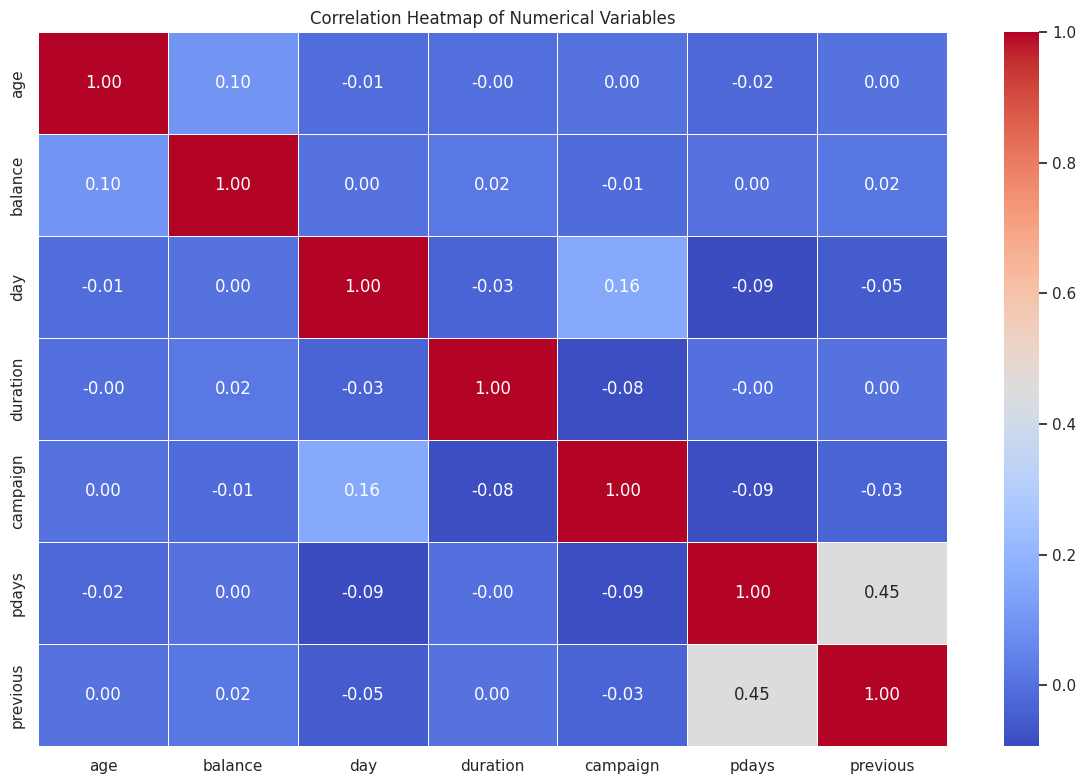

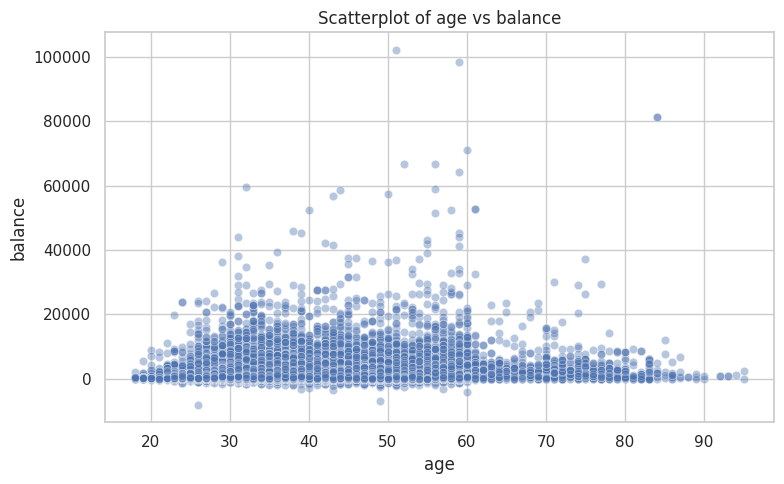

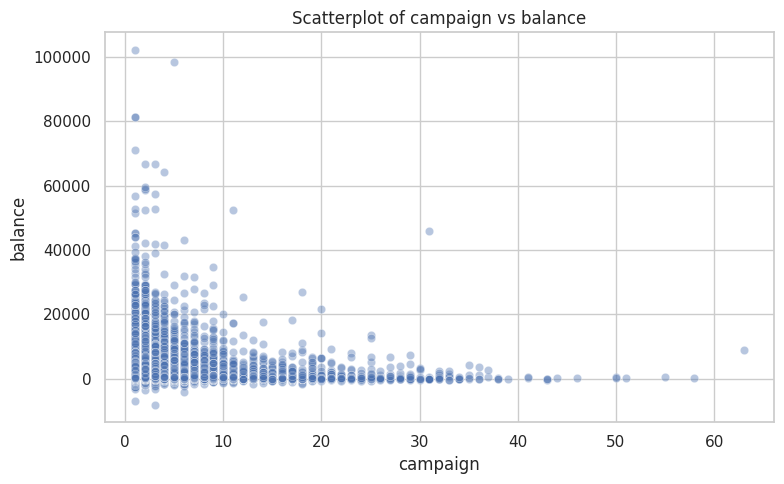

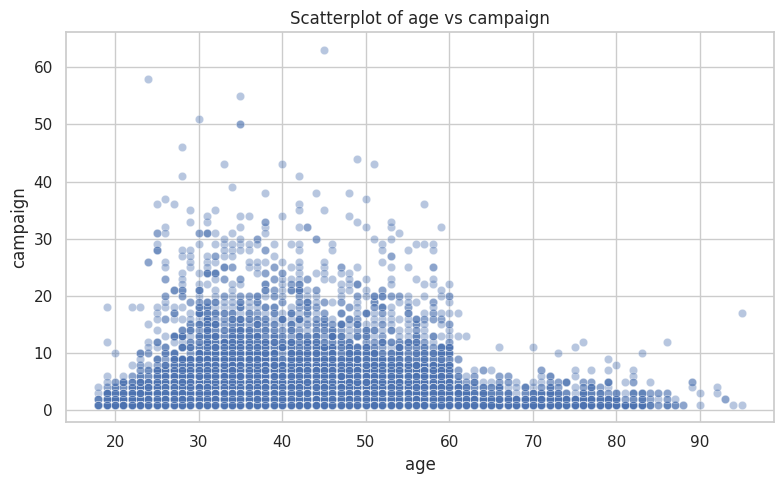

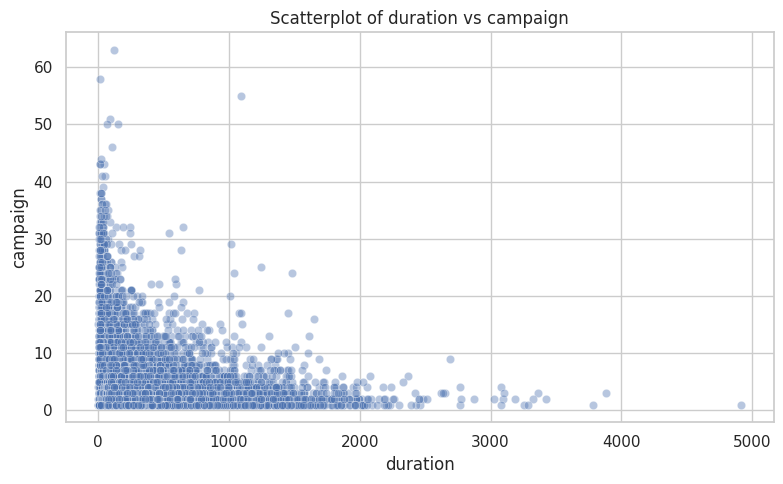

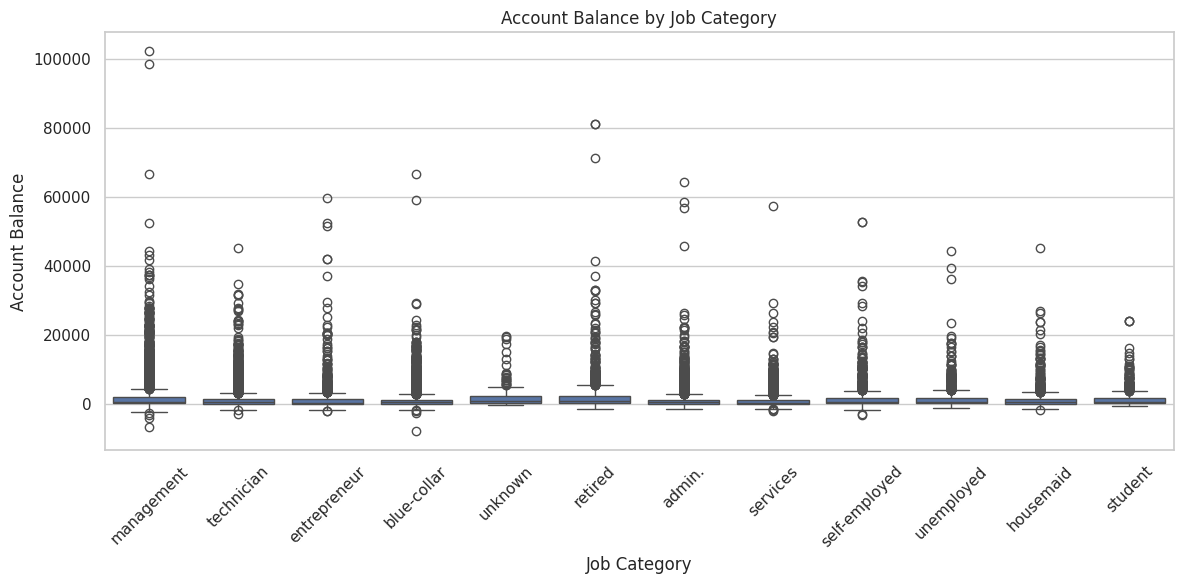

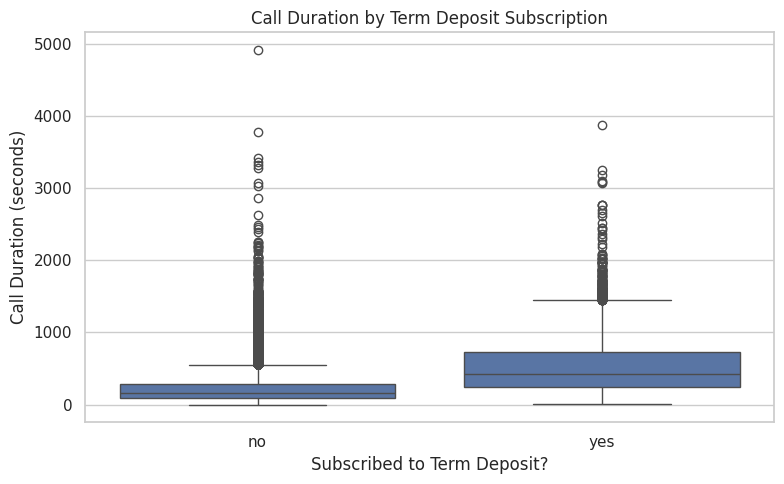

 Job Category vs Term Deposit Subscription:


y,no,yes
job,,
admin.,4541,631
blue-collar,9024,708
entrepreneur,1364,123
housemaid,1131,109
management,8159,1301
retired,1748,516
self-employed,1392,187
services,3785,369
student,669,269


In [34]:
#Correlation matrix and heatmap
numeric_cols = df.select_dtypes(include="number").columns

correlation_matrix = df[numeric_cols].corr()

print("Correlation Matrix:")
display(correlation_matrix.round(2))

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()


# Scatterplots for numerical variables
pairs = [
    ("age", "balance"),
    ("campaign", "balance"),
    ("age", "campaign"),
    ("duration", "campaign")
]

for x, y in pairs:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=df,
        x=x,
        y=y,
        alpha=0.4
    )
    plt.title(f"Scatterplot of {x} vs {y}")
    plt.tight_layout()
    plt.show()

#Compare the distributions of a numeric variable across categories.
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="job",
    y="balance"
)

plt.title("Account Balance by Job Category")
plt.xlabel("Job Category")
plt.ylabel("Account Balance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="y",
    y="duration"
)

#Duration of calls across subscription outcomes
plt.title("Call Duration by Term Deposit Subscription")
plt.xlabel("Subscribed to Term Deposit?")
plt.ylabel("Call Duration (seconds)")
plt.tight_layout()
plt.show()


#Contingency table for categorical variables
contingency_table = pd.crosstab(
    df["job"],
    df["y"]
)
print(" Job Category vs Term Deposit Subscription:")
display(contingency_table)

## 4. Principal Component Analysis (PCA) and clustering


Number of encoded variables: 42
Components needed for at least 80% variance: 26
Cumulative variance explained (%): 82.04


,Component,Individual Variance (%),Cumulative Variance (%)
0,PC1,7.18,7.18
1,PC2,6.36,13.54
2,PC3,5.59,19.13
3,PC4,4.60,23.73
4,PC5,4.02,27.75
5,PC6,3.34,31.10
6,PC7,3.29,34.38
7,PC8,3.09,37.47
8,PC9,2.98,40.45
9,PC10,2.88,43.33


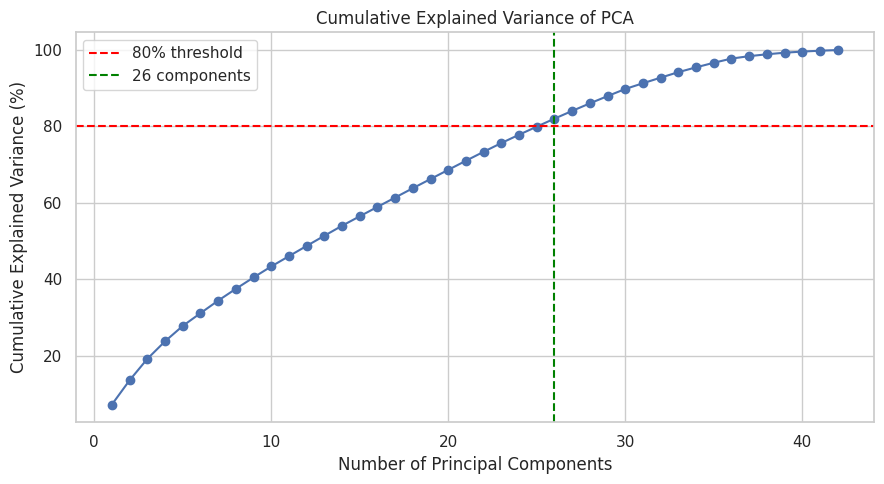

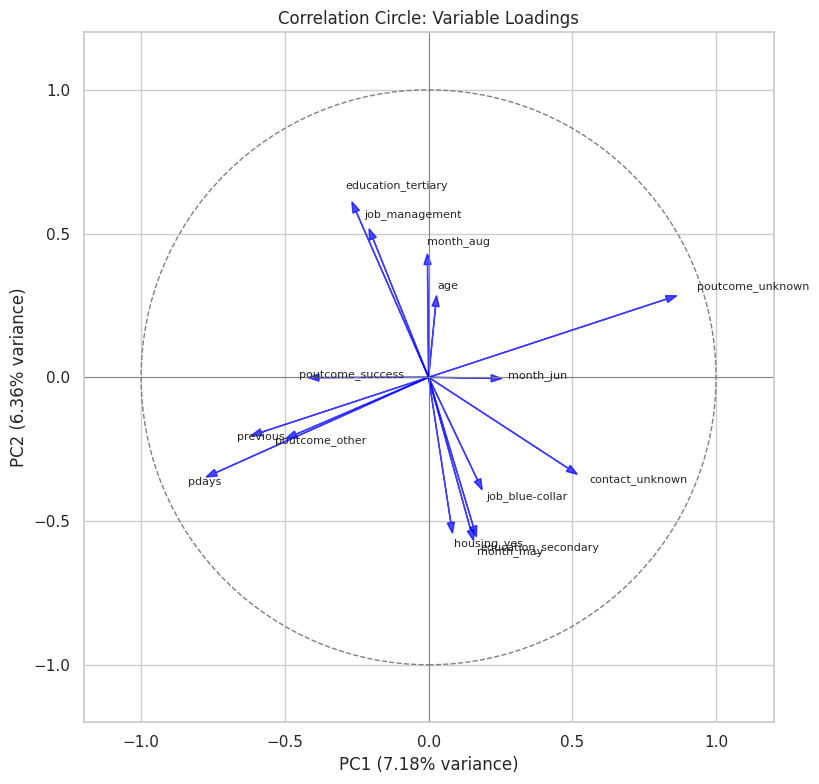

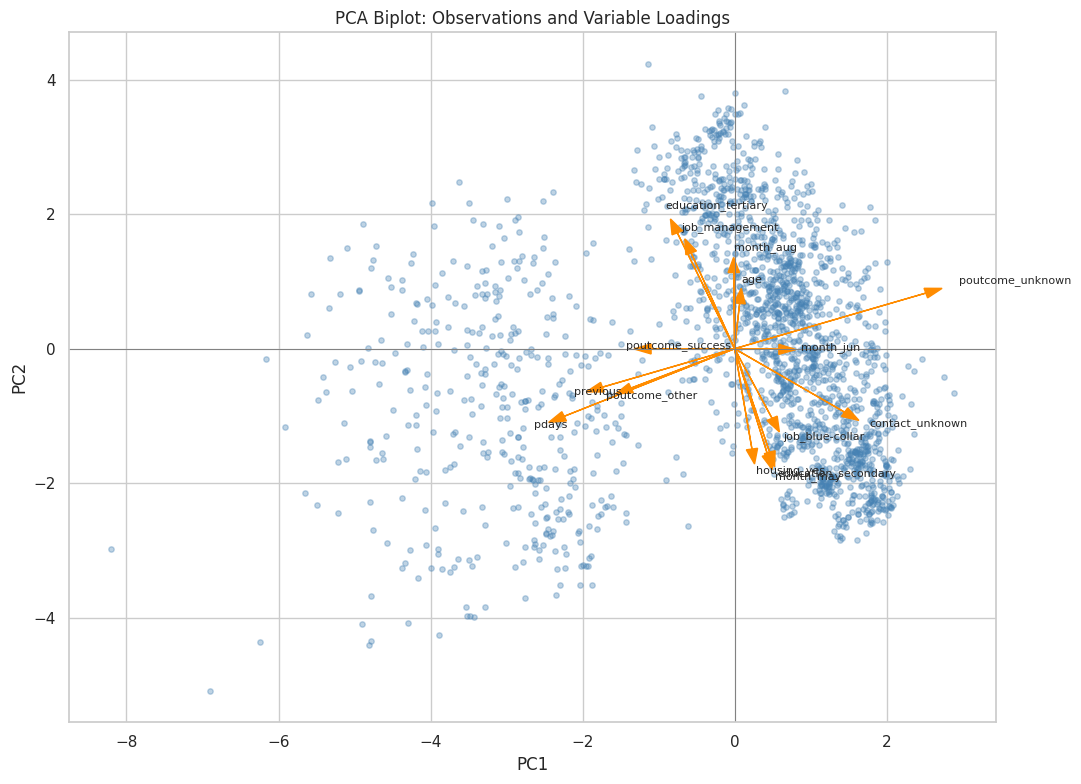

Variables with the largest absolute loadings on PC1:


,PC1,PC2
poutcome_unknown,0.863,0.284
pdays,-0.774,-0.347
previous,-0.618,-0.203
contact_unknown,0.517,-0.337
poutcome_other,-0.496,-0.213
poutcome_success,-0.419,-0.001
education_tertiary,-0.267,0.610
month_jun,0.255,-0.004
month_feb,-0.208,0.005
job_management,-0.207,0.517


Variables with the largest absolute loadings on PC2:


,PC1,PC2
education_tertiary,-0.267,0.610
month_may,0.157,-0.568
education_secondary,0.166,-0.555
housing_yes,0.083,-0.542
job_management,-0.207,0.517
month_aug,-0.004,0.430
job_blue-collar,0.187,-0.392
pdays,-0.774,-0.347
contact_unknown,0.517,-0.337
age,0.028,0.284


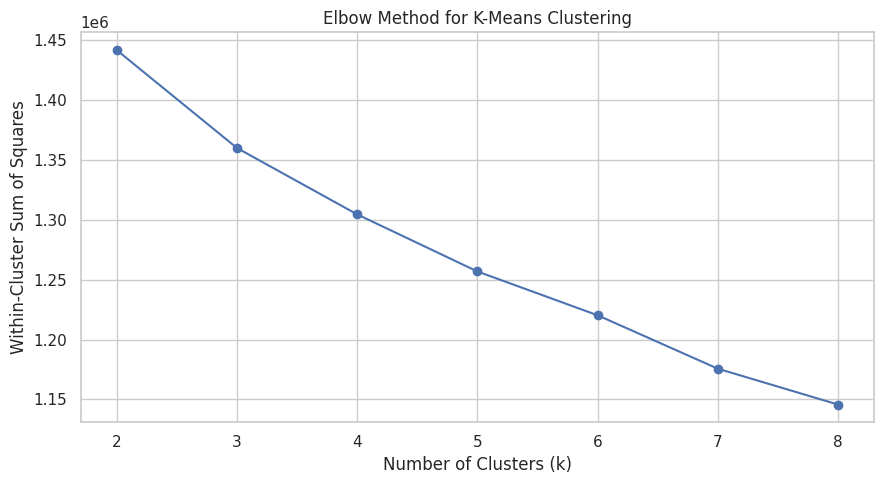

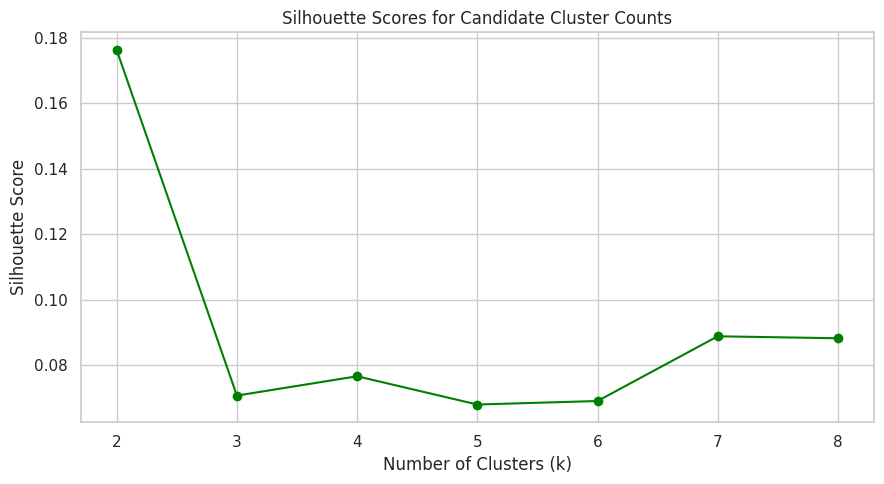

Candidate cluster counts: [2, 3, 4, 5, 6, 7, 8]
Silhouette scores: [0.1763 0.0706 0.0765 0.0679 0.069  0.0888 0.0882]
Optimal candidate k based on silhouette: 2
Number of observations per cluster:


,Observations
Cluster,
0,8212
1,37002


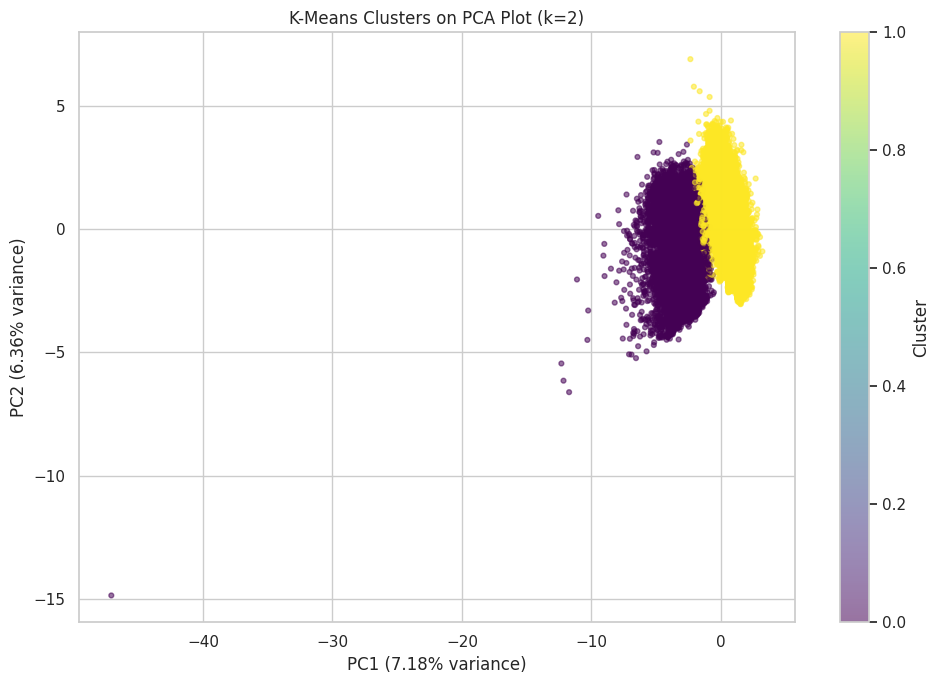

Final silhouette score: 0.1763
Mean numerical values by cluster:


,age,balance,day,duration,campaign,pdays,previous
Cluster,,,,,,,
0,40.95,1557.00,14.27,260.12,2.06,225.50,3.19
1,40.93,1319.02,16.15,257.72,2.92,-0.93,0.00


In [35]:

# Exclude the target variable from PCA and clustering
X = df.drop(columns=["y"], errors="ignore").copy()

# Identify numerical and categorical variables
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Handle missing values
for col in numeric_features:
    X[col] = X[col].fillna(X[col].median())

for col in categorical_features:
    mode = X[col].mode()
    X[col] = X[col].fillna(
        mode.iloc[0] if not mode.empty else "Unknown"
    )

# Encode categorical variables
X_encoded = pd.get_dummies(
    X,
    columns=categorical_features,
    drop_first=True,
    dtype=int
)

# Standardize all features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Determine components needed for at least 80% variance
n_components_80 = np.argmax(cumulative_variance >= 0.80) + 1

print("Number of encoded variables:", X_encoded.shape[1])
print("Components needed for at least 80% variance:",
      n_components_80)
print("Cumulative variance explained (%):",
      round(cumulative_variance[n_components_80 - 1] * 100, 2))

# Explained variance table
variance_table = pd.DataFrame({
    "Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Individual Variance (%)": explained_variance * 100,
    "Cumulative Variance (%)": cumulative_variance * 100
})

display(variance_table.round(2))

# Scree plot
plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)
plt.axhline(80, color="red", linestyle="--",
            label="80% threshold")
plt.axvline(n_components_80, color="green", linestyle="--",
            label=f"{n_components_80} components")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance of PCA")
plt.legend()
plt.tight_layout()
plt.show()



# Calculate loadings for PC1 and PC2

loadings = (
    pca.components_.T[:, :2]
    * np.sqrt(pca.explained_variance_[:2])
)

loading_df = pd.DataFrame(
    loadings,
    index=X_encoded.columns,
    columns=["PC1", "PC2"]
)

# Select the strongest variables for readability
loading_df["Strength"] = np.sqrt(
    loading_df["PC1"]**2 + loading_df["PC2"]**2
)
top_loadings = loading_df.nlargest(15, "Strength")

# Correlation circle
fig, ax = plt.subplots(figsize=(10, 8))

circle = plt.Circle(
    (0, 0), 1, fill=False, color="gray", linestyle="--"
)
ax.add_patch(circle)
ax.axhline(0, color="gray", linewidth=0.7)
ax.axvline(0, color="gray", linewidth=0.7)

for variable, row in top_loadings.iterrows():
    ax.arrow(
        0, 0, row["PC1"], row["PC2"],
        head_width=0.025,
        length_includes_head=True,
        color="blue",
        alpha=0.7
    )
    ax.text(
        row["PC1"] * 1.08,
        row["PC2"] * 1.08,
        variable,
        fontsize=8
    )

ax.set_xlim(-1.2, 1.2)
ax.set_ylim(-1.2, 1.2)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(
    f"PC1 ({explained_variance[0]*100:.2f}% variance)"
)
ax.set_ylabel(
    f"PC2 ({explained_variance[1]*100:.2f}% variance)"
)
ax.set_title("Correlation Circle: Variable Loadings")
plt.tight_layout()
plt.show()

# Biplot using a sample of observations
rng = np.random.default_rng(42)
sample_size = min(2000, len(X_pca))
sample_idx = rng.choice(
    len(X_pca), sample_size, replace=False
)
scores = X_pca[sample_idx, :2]

max_score = max(
    np.percentile(np.abs(scores[:, 0]), 95),
    np.percentile(np.abs(scores[:, 1]), 95)
)
max_loading = top_loadings[["PC1", "PC2"]].abs().to_numpy().max()
arrow_scale = 0.7 * max_score / max_loading if max_loading > 0 else 1

fig, ax = plt.subplots(figsize=(11, 8))

ax.scatter(
    scores[:, 0], scores[:, 1],
    alpha=0.35, s=15, color="steelblue"
)

for variable, row in top_loadings.iterrows():
    x_arrow = row["PC1"] * arrow_scale
    y_arrow = row["PC2"] * arrow_scale

    ax.arrow(
        0, 0, x_arrow, y_arrow,
        color="darkorange",
        head_width=0.15,
        length_includes_head=True
    )
    ax.text(
        x_arrow * 1.08,
        y_arrow * 1.08,
        variable,
        fontsize=8
    )

ax.axhline(0, color="gray", linewidth=0.7)
ax.axvline(0, color="gray", linewidth=0.7)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("PCA Biplot: Observations and Variable Loadings")
plt.tight_layout()
plt.show()

# Identify the strongest contributors to each component
print("Variables with the largest absolute loadings on PC1:")
display(
    loading_df.loc[
        loading_df["PC1"].abs().nlargest(10).index,
        ["PC1", "PC2"]
    ].round(3)
)

print("Variables with the largest absolute loadings on PC2:")
display(
    loading_df.loc[
        loading_df["PC2"].abs().nlargest(10).index,
        ["PC1", "PC2"]
    ].round(3)
)

#K clustering algorithm
# Determine the optimal number of clusters

X_pca_reduced = X_pca[:, :n_components_80]

k_values = range(2, 9)
inertias = []
silhouette_scores = []

# Sample observations for silhouette evaluation
silhouette_size = min(3000, len(X_pca_reduced))
silhouette_idx = rng.choice(
    len(X_pca_reduced),
    silhouette_size,
    replace=False
)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_pca_reduced)

    inertias.append(model.inertia_)

    score = silhouette_score(
        X_pca_reduced[silhouette_idx],
        labels[silhouette_idx]
    )
    silhouette_scores.append(score)

# Elbow method
plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares")
plt.title("Elbow Method for K-Means Clustering")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Silhouette scores
plt.figure(figsize=(9, 5))
plt.plot(k_values, silhouette_scores, marker="o", color="green")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Scores for Candidate Cluster Counts")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

# Select the candidate with the highest silhouette score
best_k = list(k_values)[np.argmax(silhouette_scores)]

print("Candidate cluster counts:", list(k_values))
print("Silhouette scores:",
      np.round(silhouette_scores, 4))
print("Optimal candidate k based on silhouette:", best_k)


# clustering and visualization

final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

clusters = final_model.fit_predict(X_pca_reduced)

# cluster labels
df_clustered = df.copy()
df_clustered["Cluster"] = clusters

# Cluster sizes
print("Number of observations per cluster:")
display(
    df_clustered["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Observations")
)

# Visualize clusters using PC1 and PC2
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    alpha=0.55,
    s=12
)

plt.xlabel(
    f"PC1 ({explained_variance[0]*100:.2f}% variance)"
)
plt.ylabel(
    f"PC2 ({explained_variance[1]*100:.2f}% variance)"
)
plt.title(f"K-Means Clusters on PCA Plot (k={best_k})")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

# Evaluate final cluster separation
final_silhouette = silhouette_score(
    X_pca_reduced[silhouette_idx],
    clusters[silhouette_idx]
)

print(f"Final silhouette score: {final_silhouette:.4f}")

# Compare original numeric characteristics between clusters
print("Mean numerical values by cluster:")
display(
    df_clustered.groupby("Cluster")[numeric_features]
    .mean()
    .round(2)
)


## 5. Summary and interpretation

Bank Marketing dataset contains information about bank clients and marketing initiatives aimed at promoting term deposits. In addition to categorical data like work, marital status, education, and contact mode, it also includes numerical variables like age, account balance, call duration, and number of campaign contacts. Descriptive statistics, correlation analysis, Principal Component Analysis (PCA), visualizations, and K-means clustering were employed in the analysis to investigate customer attributes and correlations between variables.

The analysis can be used to look at a number of intriguing patterns. While the boxplots show variations in account balances across job categories and call durations between clients who subscribed to a term deposit and those who did not, the correlation and scatterplots aid in determining correlations between numerical variables. PCA highlights the factors that contribute most strongly to the principal components while reducing the dimensionality of the encoded data. Although the degree of separation between these categories relies on the resulting cluster plot and silhouette score, K-means clustering further finds client groups with comparable features.